# Домашнее задание «Функции потерь и оптимизация»

**Автор:** Александра Бужор (Telegram: [@Angry_C_F_O](https://t.me/Angry_C_F_O))

**Цель:** изучить применение методов оптимизации для решения задачи классификации.

**Этапы работы**

1. Загрузить датасет Iris (из `sklearn`) и оставить два класса: *Iris Versicolor* и *Iris Virginica*.
2. Самостоятельно реализовать логистическую регрессию без `LogisticRegression` из `sklearn` и оформить её в виде класса.
3. Реализовать градиентный спуск, обучить им модель и посчитать метрику качества. Метрика одна и та же для всех пунктов.
4. Повторить п. 3 для метода RMSProp (Root Mean Square Propagation).
5. Повторить п. 3 для Nadam (Nesterov-accelerated Adaptive Moment Estimation).
6. Сравнить методы в таблице |метод|метрика|время работы| и сделать вывод.

Теоретическая база: статья [«Методы оптимизации нейронных сетей»](https://habr.com/en/articles/318970/) (Хабр), обзор S. Ruder [An overview of gradient descent optimization algorithms](https://arxiv.org/abs/1609.04747) и T. Dozat [Incorporating Nesterov Momentum into Adam](https://openreview.net/pdf/OM0jvwB8jIp57ZJjtNEZ.pdf) (2016).

**Содержание**

1. Загрузка и подготовка данных
2. Разбиение на выборки и стандартизация
3. Логистическая регрессия: модель, функция потерь, градиент, оптимизаторы
4. Метрика и протокол эксперимента
5. Градиентный спуск (п. 3 задания)
6. RMSProp (п. 4 задания)
7. Nadam (п. 5 задания)
8. Сравнение методов (п. 6 задания)
9. Дополнительный эксперимент: признаки без стандартизации
10. Проверка корректности реализации
11. Выводы

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Папка для графиков (используются в README репозитория)
IMG_DIR = Path('images')
IMG_DIR.mkdir(exist_ok=True)

pd.set_option('display.precision', 4)
pd.set_option('display.width', 140)

# Оформление графиков: светлая подложка, приглушённые оси и сетка
plt.rcParams.update({
    'figure.dpi': 110,
    'figure.facecolor': '#fcfcfb',
    'axes.facecolor': '#fcfcfb',
    'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': '#b9b8b3',
    'axes.labelcolor': '#0b0b0b',
    'axes.titleweight': 'bold',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.8,
    'xtick.color': '#52514e',
    'ytick.color': '#52514e',
    'lines.linewidth': 2,
    'legend.frameon': False,
})

# Фиксированные цвета методов и классов (палитра проверена на различимость при дальтонизме)
COLORS = {'GD': '#2a78d6', 'RMSProp': '#eb6834', 'Nadam': '#1baf7a'}
CLASS_COLORS = {'versicolor': '#2a78d6', 'virginica': '#eb6834'}

## 1. Загрузка и подготовка данных

Датасет Iris (Fisher, 1936) содержит 150 цветков трёх видов ирисов, по 50 экземпляров каждого вида.
Признаки — длина и ширина чашелистика (*sepal*) и лепестка (*petal*) в сантиметрах.

> В `sklearn` (начиная с версии 0.20) лежит исправленная по статье Фишера версия данных. Она совпадает с файлом `bezdekIris.data` из архива UCI.
> Файл `iris.data` из того же архива отличается в двух объектах (№ 35 и № 38). Оба относятся к классу *setosa*, который мы исключаем, поэтому версия данных на результат не влияет.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['species'] = df['target'].map(dict(enumerate(iris.target_names)))

FEATURES = list(iris.feature_names)
FEATURES_RU = ['Длина чашелистика, см', 'Ширина чашелистика, см',
               'Длина лепестка, см', 'Ширина лепестка, см']

print(f'Размер датасета: {df.shape}')
display(df.head())
print('Объектов по классам:')
display(df['species'].value_counts().to_frame('count'))

Размер датасета: (150, 6)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


Объектов по классам:


,count
species,
setosa,50
versicolor,50
virginica,50


Оставляем два класса — **Versicolor** и **Virginica** — и кодируем целевую переменную:
`virginica → 1` (положительный класс), `versicolor → 0`.

In [3]:
df2 = df[df['species'].isin(['versicolor', 'virginica'])].reset_index(drop=True)

X_all = df2[FEATURES].to_numpy(dtype=float)
y_all = (df2['species'] == 'virginica').astype(int).to_numpy()

print(f'X: {X_all.shape}, y: {y_all.shape}')
print(f'Баланс классов (0 = versicolor, 1 = virginica): {np.bincount(y_all)}')
print(f'Пропусков в данных: {df2[FEATURES].isna().sum().sum()}')

display(
    df2.groupby('species')[FEATURES]
       .agg(['mean', 'std'])
       .T.rename_axis(['признак', 'статистика'])
)

X: (100, 4), y: (100,)
Баланс классов (0 = versicolor, 1 = virginica): [50 50]
Пропусков в данных: 0


species                       versicolor  virginica
признак           статистика                       
sepal length (cm) mean            5.9360     6.5880
                  std             0.5162     0.6359
sepal width (cm)  mean            2.7700     2.9740
                  std             0.3138     0.3225
petal length (cm) mean            4.2600     5.5520
                  std             0.4699     0.5519
petal width (cm)  mean            1.3260     2.0260
                  std             0.1978     0.2747

Визуализируем два класса: слева — проекция на две главные компоненты (как в [примере sklearn с PCA](https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html)), справа — два самых информативных признака (размеры лепестка).

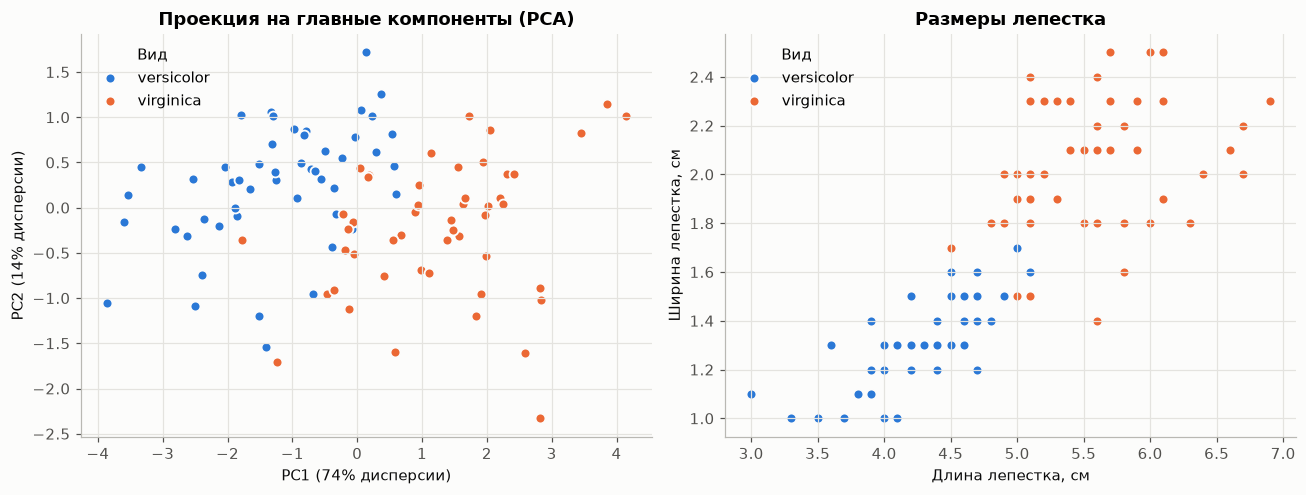

In [4]:
X_vis = (X_all - X_all.mean(axis=0)) / X_all.std(axis=0)
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_vis)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, label in [('versicolor', 0), ('virginica', 1)]:
    mask = y_all == label
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], s=42, c=CLASS_COLORS[name],
                    edgecolors='#fcfcfb', linewidths=1.2, label=name)
    axes[1].scatter(X_all[mask, 2], X_all[mask, 3], s=42, c=CLASS_COLORS[name],
                    edgecolors='#fcfcfb', linewidths=1.2, label=name)

ev = pca.explained_variance_ratio_
axes[0].set(title='Проекция на главные компоненты (PCA)',
            xlabel=f'PC1 ({ev[0]:.0%} дисперсии)', ylabel=f'PC2 ({ev[1]:.0%} дисперсии)')
axes[1].set(title='Размеры лепестка', xlabel=FEATURES_RU[2], ylabel=FEATURES_RU[3])
for ax in axes:
    ax.legend(title='Вид', loc='best')
plt.tight_layout()
plt.savefig(IMG_DIR / 'eda.png', bbox_inches='tight')
plt.show()

**Наблюдения.** Классы в основном разделимы, но на границе пересекаются: несколько объектов *versicolor* и *virginica* имеют почти одинаковые размеры лепестка.
Значит, классы **линейно неразделимы**. Для логистической регрессии это удобно: у функции потерь есть единственный конечный минимум, и веса не уходят в бесконечность.
Точность около 95 % — естественный потолок для линейной модели на этих данных.

## 2. Разбиение на выборки и стандартизация

* Обучающая и тестовая выборки — 80 / 20 со стратификацией по классу (по 40 и по 10 объектов каждого класса).
* Признаки **стандартизируем** (вычитаем среднее, делим на стандартное отклонение). Параметры стандартизации считаем только по train, чтобы информация из теста не попала в обучение.
  Для градиентных методов это важно: при разном масштабе признаков линии уровня функции потерь вытягиваются, и простой градиентный спуск сходится медленно. Отдельно проверим это в разделе 9.

In [5]:
class StandardScalerNP:
    # Стандартизация признаков на numpy: (x - mean) / std, параметры считаются по train.

    def fit(self, X):
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        return self

    def transform(self, X):
        return (X - self.mean_) / self.std_

    def fit_transform(self, X):
        return self.fit(X).transform(X)


X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, stratify=y_all, random_state=RANDOM_STATE
)

scaler = StandardScalerNP().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)

print(f'train: {X_train_s.shape}, классы {np.bincount(y_train)}')
print(f'test:  {X_test_s.shape}, классы {np.bincount(y_test)}')
print('Средние признаков train после стандартизации:', X_train_s.mean(axis=0).round(10))
print('Ст. отклонения train после стандартизации:  ', X_train_s.std(axis=0).round(10))

train: (80, 4), классы [40 40]
test:  (20, 4), классы [10 10]
Средние признаков train после стандартизации: [-0. -0. -0. -0.]
Ст. отклонения train после стандартизации:   [1. 1. 1. 1.]


## 3. Логистическая регрессия

### 3.1. Модель, функция потерь и градиент

К признакам добавляем столбец единиц, чтобы свободный член $w_0$ входил в вектор весов $w$. Тогда модель имеет вид

$$p_i = P(y_i = 1 \mid x_i) = \sigma(w^\top x_i), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}.$$

Функция потерь — **логистическая (log-loss, бинарная кросс-энтропия)**, то есть отрицательное лог-правдоподобие:

$$L(w) = -\frac{1}{n}\sum_{i=1}^{n}\Big[y_i \ln p_i + (1 - y_i)\ln(1 - p_i)\Big].$$

Её градиент получается компактным (используем $\sigma'(z) = \sigma(z)\,(1-\sigma(z))$):

$$\nabla_w L(w) = \frac{1}{n} X^\top (p - y).$$

$L(w)$ — **выпуклая** функция. Классы линейно неразделимы, поэтому минимум единственный.
Отсюда следует, что все корректно настроенные оптимизаторы должны прийти в одну и ту же точку $w^*$. Сравнивать их имеет смысл по скорости и устойчивости сходимости, а также по чувствительности к выбору шага.

Для численной устойчивости сигмоида вычисляется по-разному для $z \ge 0$ и $z < 0$: так `exp` не переполняется при больших $|z|$. Вероятности в log-loss ограничены отрезком $[10^{-15},\, 1 - 10^{-15}]$.

In [6]:
def add_intercept(X):
    # Добавляет столбец единиц для свободного члена w0.
    return np.hstack([np.ones((X.shape[0], 1)), X])


def sigmoid(z):
    # Численно устойчивая сигмоида.
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def log_loss(y_true, p, eps=1e-15):
    # Логистическая функция потерь (бинарная кросс-энтропия).
    p = np.clip(p, eps, 1 - eps)
    return float(-np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p)))


def log_loss_gradient(Xb, y_true, w):
    # Градиент log-loss по весам: X^T (p - y) / n.
    p = sigmoid(Xb @ w)
    return Xb.T @ (p - y_true) / len(y_true)


def accuracy(y_true, y_pred):
    # Доля верных ответов.
    return float(np.mean(np.asarray(y_true) == np.asarray(y_pred)))

**Проверка градиента.** Сравним аналитический градиент с численным (центральная разность) в случайной точке. Расхождение должно быть порядка $10^{-9}$ и меньше.

In [7]:
rng = np.random.default_rng(RANDOM_STATE)
Xb_train = add_intercept(X_train_s)
w_rand = rng.normal(size=Xb_train.shape[1])

analytic = log_loss_gradient(Xb_train, y_train, w_rand)
h = 1e-6
numeric = np.array([
    (log_loss(y_train, sigmoid(Xb_train @ (w_rand + h * e)))
     - log_loss(y_train, sigmoid(Xb_train @ (w_rand - h * e)))) / (2 * h)
    for e in np.eye(len(w_rand))
])

print('Аналитический градиент:', analytic.round(6))
print('Численный градиент:    ', numeric.round(6))
print(f'Максимальное расхождение: {np.abs(analytic - numeric).max():.2e}')

Аналитический градиент: [ 0.061507 -0.44597  -0.270033 -0.614472 -0.691331]
Численный градиент:     [ 0.061507 -0.44597  -0.270033 -0.614472 -0.691331]
Максимальное расхождение: 1.52e-10


### 3.2. Оптимизаторы

Обозначим $g_t = \nabla_w L(w_t)$. Все оптимизаторы оформлены как классы с единым интерфейсом: `reset()` обнуляет внутреннее состояние, `step(w, grad)` возвращает обновлённые веса. Модель от этого не зависит от конкретного метода (паттерн «Стратегия»).

**Градиентный спуск (GD).** Шаг против градиента с постоянной скоростью обучения $\eta$:

$$w_{t+1} = w_t - \eta\, g_t.$$

**RMSProp.** Для каждого параметра хранится экспоненциальное скользящее среднее квадратов градиента. Шаг делится на его корень: по «крутым» направлениям шаги уменьшаются, по пологим — увеличиваются (формулы по статье на Хабре):

$$E[g^2]_t = \gamma\, E[g^2]_{t-1} + (1-\gamma)\, g_t^2, \qquad
w_{t+1} = w_t - \frac{\eta}{\sqrt{E[g^2]_t + \varepsilon}}\, g_t.$$

**Nadam.** Это Adam (импульс $m_t$ плюс адаптивный масштаб $v_t$ с поправкой на смещение) с «заглядыванием вперёд» по Нестерову.
В конце раздела про Adam автор статьи на Хабре предлагает именно такое улучшение. Формулы — по обзору S. Ruder (2016), упрощённая версия Nadam из работы T. Dozat:

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)\, g_t, \qquad v_t = \beta_2 v_{t-1} + (1-\beta_2)\, g_t^2,$$

$$\hat m_t = \frac{m_t}{1-\beta_1^t}, \qquad \hat v_t = \frac{v_t}{1-\beta_2^t},$$

$$w_{t+1} = w_t - \frac{\eta}{\sqrt{\hat v_t} + \varepsilon}\left(\beta_1 \hat m_t + \frac{(1-\beta_1)\, g_t}{1-\beta_1^t}\right).$$

В обычном Adam в скобках стоит просто $\hat m_t$. В Nadam импульс берётся «на шаг вперёд» ($\beta_1 \hat m_t$), а текущий градиент учитывается сразу со своим весом. Это и есть идея Нестерова: сначала сдвигаемся по накопленному импульсу, потом корректируем направление.

Гиперпараметры, кроме $\eta$, оставляем рекомендованными: $\gamma = 0.9$ для RMSProp и $\beta_1 = 0.9$, $\beta_2 = 0.999$ для Nadam; $\varepsilon = 10^{-8}$ в обоих методах.

In [8]:
class Optimizer:
    # Базовый класс оптимизатора: единый интерфейс reset() / step().
    name = 'base'

    def __init__(self, learning_rate):
        self.learning_rate = learning_rate

    def reset(self, n_params):
        # Сбрасывает внутреннее состояние перед новым обучением.
        pass

    def step(self, w, grad):
        # Возвращает новые веса по текущим весам и градиенту.
        raise NotImplementedError

    def __repr__(self):
        return f'{self.name}(learning_rate={self.learning_rate})'


class GradientDescent(Optimizer):
    # Классический (full-batch) градиентный спуск.
    name = 'GD'

    def step(self, w, grad):
        return w - self.learning_rate * grad


class RMSProp(Optimizer):
    # RMSProp: шаг нормируется на скользящее среднее квадратов градиента.
    name = 'RMSProp'

    def __init__(self, learning_rate=0.01, gamma=0.9, eps=1e-8):
        super().__init__(learning_rate)
        self.gamma = gamma
        self.eps = eps

    def reset(self, n_params):
        self.eg2 = np.zeros(n_params)          # E[g^2]

    def step(self, w, grad):
        self.eg2 = self.gamma * self.eg2 + (1 - self.gamma) * grad ** 2
        return w - self.learning_rate * grad / np.sqrt(self.eg2 + self.eps)


class Nadam(Optimizer):
    # Nadam: Adam с импульсом Нестерова (формулировка S. Ruder, 2016).
    name = 'Nadam'

    def __init__(self, learning_rate=0.002, beta1=0.9, beta2=0.999, eps=1e-8):
        super().__init__(learning_rate)
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps

    def reset(self, n_params):
        self.m = np.zeros(n_params)            # первый момент (импульс)
        self.v = np.zeros(n_params)            # второй момент
        self.t = 0                             # номер шага

    def step(self, w, grad):
        self.t += 1
        b1, b2, t = self.beta1, self.beta2, self.t
        self.m = b1 * self.m + (1 - b1) * grad
        self.v = b2 * self.v + (1 - b2) * grad ** 2
        m_hat = self.m / (1 - b1 ** t)
        v_hat = self.v / (1 - b2 ** t)
        m_nesterov = b1 * m_hat + (1 - b1) * grad / (1 - b1 ** t)
        return w - self.learning_rate * m_nesterov / (np.sqrt(v_hat) + self.eps)

### 3.3. Класс логистической регрессии

`MyLogisticRegression` принимает объект-оптимизатор и число эпох. Обучение идёт полным батчем: одна эпоха — один шаг по градиенту на всей обучающей выборке.
Все методы стартуют из одной точки $w_0 = 0$. Это корректно, потому что функция потерь выпуклая, а сравнение получается честным.
Модель сохраняет историю значений функции потерь и весов по эпохам. По истории потом строятся кривые сходимости и считается метрика на любой эпохе.

In [9]:
class MyLogisticRegression:
    # Бинарная логистическая регрессия, обучаемая градиентным оптимизатором.
    #
    # Параметры:
    #   optimizer — объект с методами reset(n_params) и step(w, grad);
    #   n_epochs  — число эпох (full-batch: 1 эпоха = 1 шаг оптимизатора).
    #
    # Атрибуты после fit:
    #   intercept_, coef_ — свободный член и веса признаков;
    #   loss_history_     — L(w_t) для t = 0..n_epochs;
    #   coef_history_     — веса w_t для t = 0..n_epochs;
    #   fit_time_         — время обучения, с.

    def __init__(self, optimizer, n_epochs=1000):
        self.optimizer = optimizer
        self.n_epochs = n_epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        Xb = add_intercept(X)
        n = len(y)

        w = np.zeros(Xb.shape[1])
        self.optimizer.reset(w.size)
        loss_history, coef_history = [], []

        start = time.perf_counter()
        for _ in range(self.n_epochs):
            p = sigmoid(Xb @ w)
            loss_history.append(log_loss(y, p))
            coef_history.append(w.copy())
            grad = Xb.T @ (p - y) / n
            w = self.optimizer.step(w, grad)
        self.fit_time_ = time.perf_counter() - start

        loss_history.append(log_loss(y, sigmoid(Xb @ w)))
        coef_history.append(w.copy())
        self.loss_history_ = np.array(loss_history)
        self.coef_history_ = np.array(coef_history)
        self.w_ = w
        self.intercept_, self.coef_ = w[0], w[1:]
        return self

    def predict_proba(self, X):
        # Вероятность положительного класса (virginica).
        return sigmoid(add_intercept(np.asarray(X, dtype=float)) @ self.w_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

    def score(self, X, y):
        # Метрика качества — accuracy.
        return accuracy(y, self.predict(X))

    def staged_accuracy(self, X, y, threshold=0.5):
        # Accuracy модели после каждой эпохи (по сохранённой истории весов).
        proba = sigmoid(add_intercept(np.asarray(X, dtype=float)) @ self.coef_history_.T)
        return ((proba >= threshold) == np.asarray(y)[:, None]).mean(axis=0)

## 4. Метрика и протокол эксперимента

### Метрика качества — accuracy

Метрика одна для всех методов — **accuracy** (доля верно классифицированных цветков). Почему она:
* классы сбалансированы (50/50, в тесте 10/10), поэтому accuracy не искажается перекосом классов;
* ошибки в обе стороны одинаково нежелательны, то есть цены ошибок симметричны;
* метрику легко интерпретировать.

В тесте всего 20 объектов, и одна ошибка меняет accuracy на 5 п.п. Поэтому ту же метрику дополнительно оцениваем **повторённой стратифицированной кросс-валидацией** (5 фолдов × 10 повторов) на всех 100 объектах. Стандартизация обучается внутри каждого фолда.

### Как сравниваем оптимизаторы

Качество модели (accuracy) зависит от того, в какую точку пришёл оптимизатор. Сам оптимизатор характеризует то, **как быстро и устойчиво** он туда пришёл. Поэтому кроме метрики фиксируем:
* **эталонный минимум** $L^*$ функции потерь на train. Его находим методом Ньютона — методом второго порядка, о котором упоминает статья. Для 5 параметров гессиан считается легко;
* **число эпох до сходимости** — первую эпоху, начиная с которой $L(w_t) - L^* < \varepsilon = 10^{-4}$ и разрыв больше не превышает $\varepsilon$ (критерий устойчивой сходимости: отсекает «проскоки» и колебания);
* **время обучения** — время 1000 эпох (медиана 20 запусков) и время до сходимости.

### Правила, одинаковые для всех методов

* старт из $w_0 = 0$, бюджет — `N_EPOCHS = 1000` эпох полным батчем;
* скорость обучения $\eta$ выбирается **по одной и той же сетке** $\{0.001,\ 0.003,\ 0.01,\ \dots,\ 3,\ 10\}$. Берём шаг с наименьшим числом эпох до сходимости; если ни один шаг не сошёлся, берём шаг с наименьшей итоговой потерей;
* шаг подбирается **только по train и только по функции потерь**. Тестовая выборка и accuracy в подборе не участвуют, поэтому утечки нет.

In [10]:
N_EPOCHS = 1000
EPS = 1e-4
LR_GRID = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]


def newton_logreg(X, y, max_iter=50, tol=1e-12):
    # Эталонный минимум log-loss методом Ньютона (IRLS).
    Xb = add_intercept(X)
    w = np.zeros(Xb.shape[1])
    for it in range(1, max_iter + 1):
        p = sigmoid(Xb @ w)
        grad = Xb.T @ (p - y) / len(y)
        if np.linalg.norm(grad) < tol:
            break
        hess = (Xb * (p * (1 - p))[:, None]).T @ Xb / len(y)
        w = w - np.linalg.solve(hess, grad)
    return w, log_loss(y, sigmoid(Xb @ w)), it


w_star, loss_star, newton_iters = newton_logreg(X_train_s, y_train)
print(f'Метод Ньютона: {newton_iters} итераций')
print(f'L* (минимум log-loss на train) = {loss_star:.10f}')
print('w* =', w_star.round(4), '(w0, затем признаки)')

Метод Ньютона: 12 итераций
L* (минимум log-loss на train) = 0.0532977401
w* = [ 0.4477 -1.1384 -0.8174  5.5039  6.5176] (w0, затем признаки)


In [11]:
def epochs_to_converge(loss_history, loss_star, eps=EPS):
    # Эпоха, начиная с которой L(w_t) - L* < eps для всех последующих эпох.
    # None — не сошёлся за отведённый бюджет.
    gap = np.asarray(loss_history) - loss_star
    above = np.flatnonzero(~(gap < eps))       # NaN (расходимость) тоже считаем «выше»
    if above.size == 0:
        return 0
    if above[-1] == len(gap) - 1:
        return None
    return int(above[-1] + 1)


def select_learning_rate(optimizer_cls, X, y, loss_star, grid=LR_GRID, n_epochs=N_EPOCHS):
    # Подбор шага по сетке: минимум эпох до сходимости, иначе минимум итоговой потери.
    rows = []
    for lr in grid:
        with np.errstate(all='ignore'):
            model = MyLogisticRegression(optimizer_cls(learning_rate=lr), n_epochs).fit(X, y)
        rows.append({
            'Шаг η': lr,
            'L(w_final) − L*': model.loss_history_[-1] - loss_star,
            'Эпох до сходимости': epochs_to_converge(model.loss_history_, loss_star),
        })
    table = pd.DataFrame(rows)
    table['Эпох до сходимости'] = table['Эпох до сходимости'].astype('Int64')

    converged = table.dropna(subset=['Эпох до сходимости'])
    if len(converged):
        best = converged.sort_values(['Эпох до сходимости', 'Шаг η']).iloc[0]
    else:
        best = table.sort_values('L(w_final) − L*', na_position='last').iloc[0]
    return float(best['Шаг η']), table


def cross_val_accuracy(make_optimizer, X, y, n_epochs=N_EPOCHS, n_splits=5, n_repeats=10):
    # Repeated stratified K-fold: accuracy на валидации после каждой эпохи.
    # Возвращает матрицу (n_splits * n_repeats, n_epochs + 1).
    cv = RepeatedStratifiedKFold(n_splits=n_splits, n_repeats=n_repeats,
                                 random_state=RANDOM_STATE)
    curves = []
    for tr_idx, val_idx in cv.split(X, y):
        fold_scaler = StandardScalerNP().fit(X[tr_idx])
        model = MyLogisticRegression(make_optimizer(), n_epochs).fit(
            fold_scaler.transform(X[tr_idx]), y[tr_idx])
        curves.append(model.staged_accuracy(fold_scaler.transform(X[val_idx]), y[val_idx]))
    return np.array(curves)


def measure_fit_time(make_optimizer, X, y, n_epochs=N_EPOCHS, n_runs=20):
    # Медианное время обучения за n_runs запусков, секунды.
    times = [MyLogisticRegression(make_optimizer(), n_epochs).fit(X, y).fit_time_
             for _ in range(n_runs)]
    return float(np.median(times))


def run_method(optimizer_cls):
    # Полный цикл для одного оптимизатора: подбор шага, обучение, метрики, CV, время.
    lr, grid_table = select_learning_rate(optimizer_cls, X_train_s, y_train, loss_star)

    def make_optimizer():
        return optimizer_cls(learning_rate=lr)

    model = MyLogisticRegression(make_optimizer(), N_EPOCHS).fit(X_train_s, y_train)
    cv_curves = cross_val_accuracy(make_optimizer, X_all, y_all)
    fit_time = measure_fit_time(make_optimizer, X_train_s, y_train)
    conv = epochs_to_converge(model.loss_history_, loss_star)

    summary = {
        'Метод': model.optimizer.name,
        'Шаг η': lr,
        'Accuracy (test)': model.score(X_test_s, y_test),
        'Accuracy (CV 5×10)': cv_curves[:, -1].mean(),
        'CV std': cv_curves[:, -1].std(),
        'Log-loss (train)': model.loss_history_[-1],
        'Эпох до сходимости': conv,
        'Время 1000 эпох, мс': fit_time * 1e3,
        'Время до сходимости, мс': fit_time * 1e3 * conv / N_EPOCHS if conv is not None else np.nan,
    }
    return {'summary': summary, 'model': model, 'grid': grid_table, 'cv_curves': cv_curves}


def report(result):
    # Печать результатов метода.
    s, model = result['summary'], result['model']
    print('Подбор шага по сетке (train, бюджет 1000 эпох):')
    display(result['grid'].style.format({'L(w_final) − L*': '{:.2e}'}, na_rep='не сошёлся')
                                .hide(axis='index'))
    print(f"Выбранный шаг η = {s['Шаг η']}")
    print(f"Эпох до сходимости (L − L* < {EPS:g}): {s['Эпох до сходимости']}")
    print(f"Log-loss на train после {N_EPOCHS} эпох: {s['Log-loss (train)']:.6f}  (L* = {loss_star:.6f})")
    print(f"Accuracy на test: {s['Accuracy (test)']:.3f}")
    print(f"Accuracy CV 5×10: {s['Accuracy (CV 5×10)']:.3f} ± {s['CV std']:.3f}")
    print(f"Время 1000 эпох: {s['Время 1000 эпох, мс']:.1f} мс")
    print('Веса модели: w0 =', round(model.intercept_, 4), '| признаки:', model.coef_.round(4))


RESULTS = {}

## 5. Градиентный спуск (п. 3 задания)

$$w_{t+1} = w_t - \eta\, \nabla_w L(w_t)$$

In [12]:
RESULTS['GD'] = run_method(GradientDescent)
report(RESULTS['GD'])

Подбор шага по сетке (train, бюджет 1000 эпох):


Шаг η,L(w_final) − L*,Эпох до сходимости
0.001000,3.89e-01,не сошёлся
0.003000,2.47e-01,не сошёлся
0.010000,1.29e-01,не сошёлся
0.030000,5.78e-02,не сошёлся
0.100000,1.83e-02,не сошёлся
0.300000,4.74e-03,не сошёлся
1.000000,5.88e-04,не сошёлся
3.000000,2.41e-05,666
10.000000,2.09e-09,157


Выбранный шаг η = 10.0
Эпох до сходимости (L − L* < 0.0001): 157
Log-loss на train после 1000 эпох: 0.053298  (L* = 0.053298)
Accuracy на test: 0.950
Accuracy CV 5×10: 0.959 ± 0.047
Время 1000 эпох: 44.8 мс
Веса модели: w0 = 0.4478 | признаки: [-1.1375 -0.8179  5.5016  6.5171]


**Почему для GD лучшим оказался такой большой шаг?** Для градиентного спуска «правильный» масштаб шага задаётся кривизной функции потерь.
Глобальная оценка константы Липшица градиента log-loss — $L_{\max} = \lambda_{\max}(X^\top X / n)\,/\,4$, отсюда гарантированно безопасный шаг $\eta \le 1/L_{\max}$.
Но вблизи минимума большинство объектов уже уверенно классифицированы ($p_i(1-p_i) \ll 1/4$). Кривизна там, то есть гессиан $H(w^*)$, намного меньше, и устойчивыми остаются шаги до $2/\lambda_{\max}(H(w^*))$.
Скорость GD определяется числом обусловленности гессиана $\kappa = \lambda_{\max}/\lambda_{\min}$: по «пологому» направлению шаг $1/L_{\max}$ слишком мал.

In [13]:
n_train = len(y_train)
p_star = sigmoid(Xb_train @ w_star)
H_star = (Xb_train * (p_star * (1 - p_star))[:, None]).T @ Xb_train / n_train
eig_H = np.linalg.eigvalsh(H_star)
L_max = np.linalg.eigvalsh(Xb_train.T @ Xb_train / n_train).max() / 4

print(f'Глобальная оценка L_max = {L_max:.3f}  →  безопасный шаг 1/L_max ≈ {1 / L_max:.2f}')
print(f'Собственные значения H(w*): {eig_H.round(4)}')
print(f'Предел устойчивости вблизи минимума 2/λmax(H*) ≈ {2 / eig_H.max():.1f}')
print(f'Число обусловленности H(w*): κ ≈ {eig_H.max() / eig_H.min():.0f}')

Глобальная оценка L_max = 0.746  →  безопасный шаг 1/L_max ≈ 1.34
Собственные значения H(w*): [0.0006 0.0012 0.0032 0.0054 0.0158]
Предел устойчивости вблизи минимума 2/λmax(H*) ≈ 126.3
Число обусловленности H(w*): κ ≈ 26


## 6. RMSProp (п. 4 задания)

$$E[g^2]_t = \gamma E[g^2]_{t-1} + (1-\gamma) g_t^2, \qquad w_{t+1} = w_t - \frac{\eta}{\sqrt{E[g^2]_t + \varepsilon}}\, g_t, \qquad \gamma = 0.9$$

In [14]:
RESULTS['RMSProp'] = run_method(RMSProp)
report(RESULTS['RMSProp'])

Подбор шага по сетке (train, бюджет 1000 эпох):


Шаг η,L(w_final) − L*,Эпох до сходимости
0.001000,1.74e-01,не сошёлся
0.003000,2.34e-02,не сошёлся
0.010000,0.00e+00,665
0.030000,2.08e-06,258
0.100000,4.00e-05,120
0.300000,3.62e-04,не сошёлся
1.000000,2.41e-03,не сошёлся
3.000000,6.36e-03,не сошёлся
10.000000,6.65e-01,не сошёлся


Выбранный шаг η = 0.1
Эпох до сходимости (L − L* < 0.0001): 120
Log-loss на train после 1000 эпох: 0.053338  (L* = 0.053298)
Accuracy на test: 0.950
Accuracy CV 5×10: 0.954 ± 0.051
Время 1000 эпох: 80.4 мс
Веса модели: w0 = 0.3985 | признаки: [-1.0918 -0.7708  5.4934  6.5594]


## 7. Nadam (п. 5 задания)

$$w_{t+1} = w_t - \frac{\eta}{\sqrt{\hat v_t} + \varepsilon}\left(\beta_1 \hat m_t + \frac{(1-\beta_1)\, g_t}{1-\beta_1^t}\right), \qquad \beta_1 = 0.9,\ \beta_2 = 0.999$$

In [15]:
RESULTS['Nadam'] = run_method(Nadam)
report(RESULTS['Nadam'])

Подбор шага по сетке (train, бюджет 1000 эпох):


Шаг η,L(w_final) − L*,Эпох до сходимости
0.001000,2.32e-01,не сошёлся
0.003000,9.02e-02,не сошёлся
0.010000,1.71e-02,не сошёлся
0.030000,1.63e-03,не сошёлся
0.100000,3.83e-06,631
0.300000,3.04e-15,219
1.000000,0.00e+00,158
3.000000,3.77e-04,не сошёлся
10.000000,0.00e+00,403


Выбранный шаг η = 1.0
Эпох до сходимости (L − L* < 0.0001): 158
Log-loss на train после 1000 эпох: 0.053298  (L* = 0.053298)
Accuracy на test: 0.950
Accuracy CV 5×10: 0.954 ± 0.051
Время 1000 эпох: 53.3 мс
Веса модели: w0 = 0.4477 | признаки: [-1.1384 -0.8174  5.5039  6.5176]


## 8. Сравнение методов (п. 6 задания)

### 8.1. Сводная таблица

In [16]:
summary = pd.DataFrame([r['summary'] for r in RESULTS.values()])
summary['Эпох до сходимости'] = summary['Эпох до сходимости'].astype('Int64')

display(
    summary.style
    .format({
        'Шаг η': '{:g}',
        'Accuracy (test)': '{:.3f}',
        'Accuracy (CV 5×10)': '{:.3f}',
        'CV std': '{:.3f}',
        'Log-loss (train)': '{:.6f}',
        'Время 1000 эпох, мс': '{:.1f}',
        'Время до сходимости, мс': '{:.1f}',
    }, na_rep='—')
    .hide(axis='index')
)

# Краткая таблица в формате задания: |метод|метрика|время работы|
short = pd.DataFrame({
    'Метод': summary['Метод'],
    'Метрика: accuracy (test)': summary['Accuracy (test)'].map('{:.3f}'.format),
    'Метрика: accuracy (CV 5×10)': [f'{m:.3f} ± {s:.3f}' for m, s in
                                    zip(summary['Accuracy (CV 5×10)'], summary['CV std'])],
    'Время работы: 1000 эпох, мс': summary['Время 1000 эпох, мс'].map('{:.1f}'.format),
    'Время до сходимости, мс': summary['Время до сходимости, мс'].map('{:.1f}'.format),
})
display(short.style.hide(axis='index'))

Метод,Шаг η,Accuracy (test),Accuracy (CV 5×10),CV std,Log-loss (train),Эпох до сходимости,"Время 1000 эпох, мс","Время до сходимости, мс"
GD,10,0.950,0.959,0.047,0.053298,157,44.8,7.0
RMSProp,0.1,0.950,0.954,0.051,0.053338,120,80.4,9.6
Nadam,1,0.950,0.954,0.051,0.053298,158,53.3,8.4


Метод,Метрика: accuracy (test),Метрика: accuracy (CV 5×10),"Время работы: 1000 эпох, мс","Время до сходимости, мс"
GD,0.950,0.959 ± 0.047,44.8,7.0
RMSProp,0.950,0.954 ± 0.051,80.4,9.6
Nadam,0.950,0.954 ± 0.051,53.3,8.4


### 8.2. Сходимость функции потерь

Разрыв $L(w_t) - L^*$ в логарифмической шкале. Пунктир — порог $\varepsilon = 10^{-4}$.

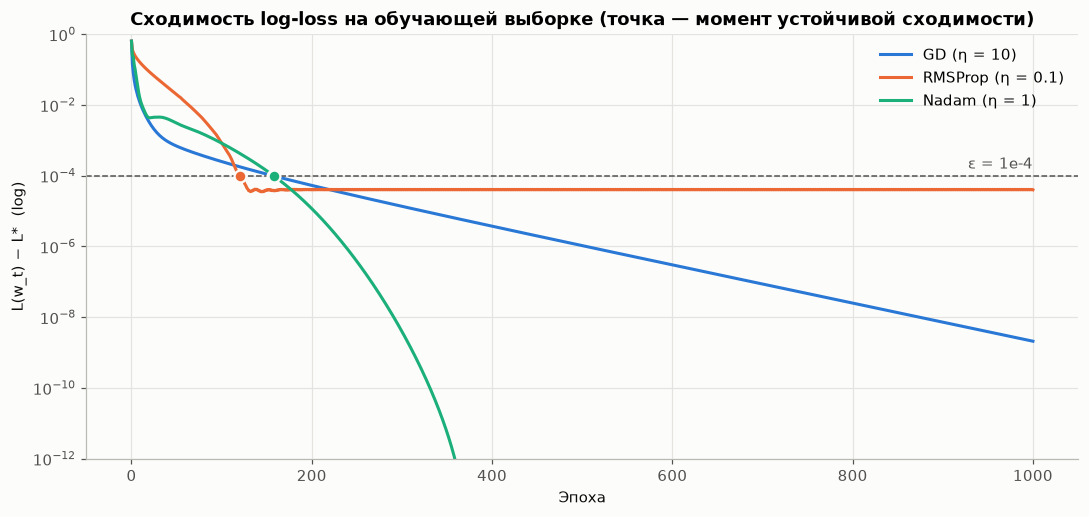

In [17]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for name, res in RESULTS.items():
    gap = np.maximum(res['model'].loss_history_ - loss_star, 1e-16)
    lr = res['summary']['Шаг η']
    ax.plot(gap, color=COLORS[name], label=f'{name} (η = {lr:g})')
    conv = res['summary']['Эпох до сходимости']
    if conv is not None:
        ax.scatter([conv], [gap[conv]], s=60, color=COLORS[name],
                   edgecolors='#fcfcfb', linewidths=1.5, zorder=5)
ax.axhline(EPS, color='#52514e', linestyle='--', linewidth=1)
ax.text(N_EPOCHS, EPS * 1.6, 'ε = 1e-4', ha='right', color='#52514e')
ax.set(yscale='log', xlabel='Эпоха', ylabel='L(w_t) − L*  (log)',
       title='Сходимость log-loss на обучающей выборке (точка — момент устойчивой сходимости)')
ax.set_ylim(1e-12, 1)
ax.legend(loc='upper right')
plt.tight_layout()
plt.savefig(IMG_DIR / 'convergence.png', bbox_inches='tight')
plt.show()

### 8.3. Метрика в зависимости от числа эпох

Средняя accuracy на кросс-валидации (5×10) после каждой эпохи показывает, как быстро метод выходит на итоговое качество.

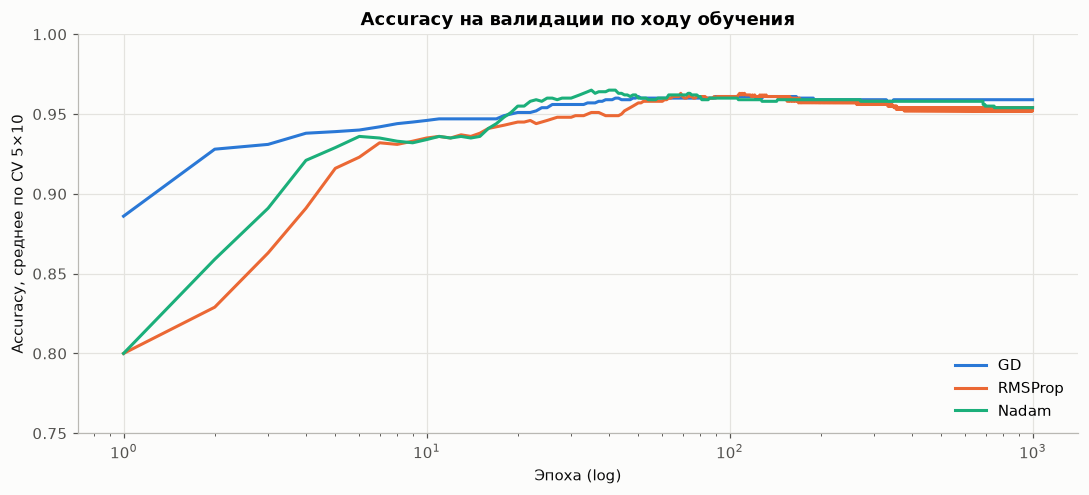

,GD,RMSProp,Nadam
Эпоха,,,
1,0.886,0.800,0.800
5,0.939,0.916,0.929
10,0.946,0.935,0.934
20,0.951,0.945,0.955
50,0.961,0.957,0.960
100,0.961,0.961,0.960
200,0.959,0.958,0.959
500,0.959,0.954,0.958
1000,0.959,0.954,0.954


In [18]:
fig, ax = plt.subplots(figsize=(10, 4.6))
epochs = np.arange(N_EPOCHS + 1)
for name, res in RESULTS.items():
    curve = res['cv_curves'].mean(axis=0)
    ax.plot(epochs[1:], curve[1:], color=COLORS[name], label=name)
ax.set(xscale='log', xlabel='Эпоха (log)', ylabel='Accuracy, среднее по CV 5×10',
       title='Accuracy на валидации по ходу обучения')
ax.set_ylim(0.75, 1.0)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(IMG_DIR / 'accuracy_vs_epoch.png', bbox_inches='tight')
plt.show()

checkpoints = [1, 5, 10, 20, 50, 100, 200, 500, 1000]
display(pd.DataFrame(
    {name: res['cv_curves'].mean(axis=0)[checkpoints] for name, res in RESULTS.items()},
    index=pd.Index(checkpoints, name='Эпоха'),
).style.format('{:.3f}'))

### 8.4. Чувствительность к скорости обучения

Итоговый разрыв $L(w_{1000}) - L^*$ для каждого шага из сетки. Чем шире область, где кривая лежит ниже порога $\varepsilon$, тем менее метод требователен к подбору $\eta$.

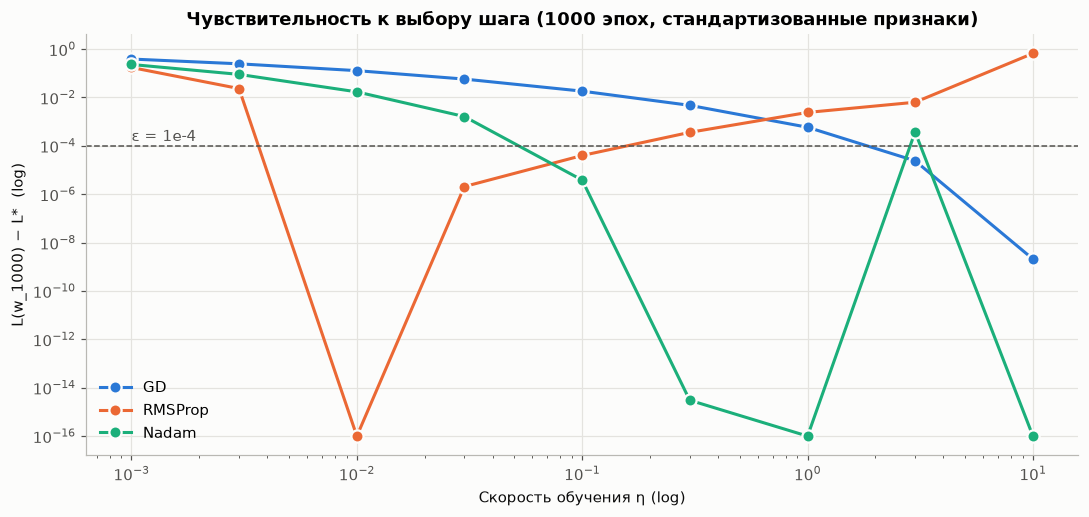

Эпох до устойчивой сходимости для каждого шага (— = не сошёлся за 1000 эпох):


,GD,RMSProp,Nadam
Шаг η,,,
0.001000,—,—,—
0.003000,—,—,—
0.010000,—,665,—
0.030000,—,258,—
0.100000,—,120,631
0.300000,—,—,219
1.000000,—,—,158
3.000000,666,—,—
10.000000,157,—,403


In [19]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for name, res in RESULTS.items():
    grid = res['grid']
    gap = np.maximum(grid['L(w_final) − L*'].to_numpy(dtype=float), 1e-16)
    ax.plot(grid['Шаг η'], gap, marker='o', markersize=8, color=COLORS[name],
            markeredgecolor='#fcfcfb', markeredgewidth=1.5, label=name)
ax.axhline(EPS, color='#52514e', linestyle='--', linewidth=1)
ax.text(LR_GRID[0], EPS * 1.6, 'ε = 1e-4', color='#52514e')
ax.set(xscale='log', yscale='log', xlabel='Скорость обучения η (log)',
       ylabel='L(w_1000) − L*  (log)',
       title='Чувствительность к выбору шага (1000 эпох, стандартизованные признаки)')
ax.legend(loc='lower left')
plt.tight_layout()
plt.savefig(IMG_DIR / 'lr_sensitivity.png', bbox_inches='tight')
plt.show()

lr_table = pd.concat(
    {name: res['grid'].set_index('Шаг η')['Эпох до сходимости'] for name, res in RESULTS.items()},
    axis=1,
)
print('Эпох до устойчивой сходимости для каждого шага (— = не сошёлся за 1000 эпох):')
display(lr_table.style.format(na_rep='—'))

### 8.5. Траектории оптимизаторов

Как в статье на Хабре, посмотрим на траектории методов. Весов пять, поэтому показываем проекцию на плоскость двух главных весов — при длине и ширине лепестка. Линии уровня построены при остальных весах, зафиксированных в оптимуме $w^*$. Это срез, а не точный рельеф, но характер движения он передаёт.

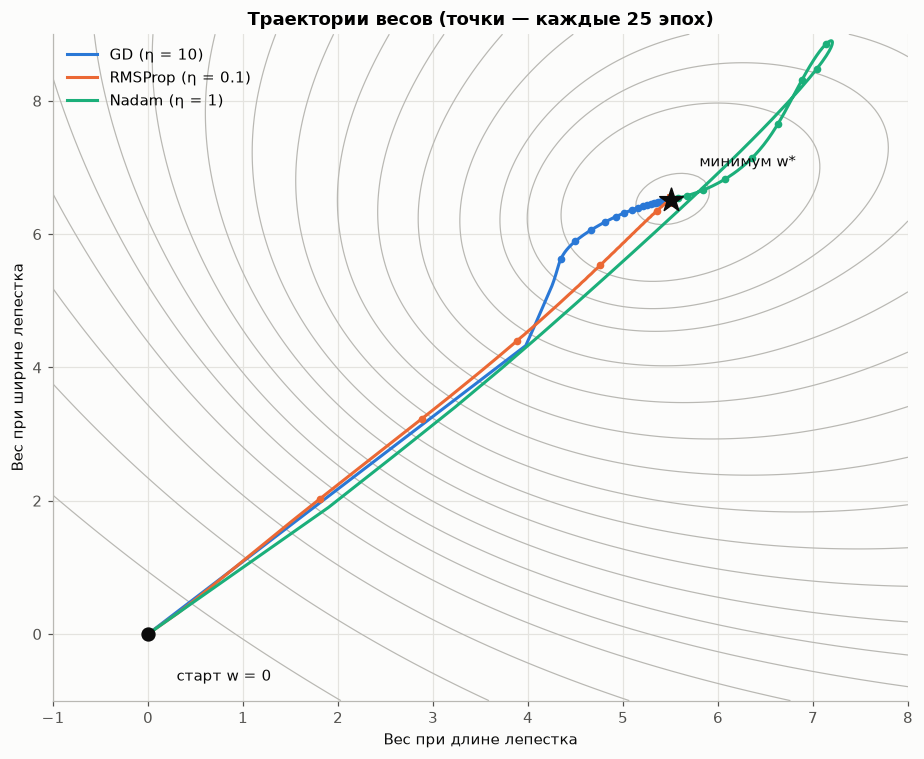

In [20]:
i, j = 3, 4  # индексы весов в векторе (w0, sepal length, sepal width, petal length, petal width)
g1, g2 = np.meshgrid(np.linspace(-1, 8, 160), np.linspace(-1, 9, 160))
W = np.tile(w_star, (g1.size, 1))
W[:, i], W[:, j] = g1.ravel(), g2.ravel()
P = sigmoid(Xb_train @ W.T)
P = np.clip(P, 1e-15, 1 - 1e-15)
Z = -(y_train[:, None] * np.log(P) + (1 - y_train[:, None]) * np.log(1 - P)).mean(axis=0)
Z = Z.reshape(g1.shape)

fig, ax = plt.subplots(figsize=(8.5, 7))
levels = np.quantile(Z, np.linspace(0.005, 0.95, 18))
cs = ax.contour(g1, g2, Z, levels=np.unique(levels), colors='#b9b8b3', linewidths=0.8)
for name, res in RESULTS.items():
    path = res['model'].coef_history_[:, [i, j]]
    ax.plot(path[:, 0], path[:, 1], color=COLORS[name], linewidth=2,
            label=f"{name} (η = {res['summary']['Шаг η']:g})")
    ax.plot(path[::25, 0], path[::25, 1], 'o', color=COLORS[name], markersize=4)
ax.scatter([0], [0], s=70, color='#0b0b0b', zorder=6)
ax.annotate('старт w = 0', (0, 0), xytext=(0.3, -0.7), color='#0b0b0b')
ax.scatter([w_star[i]], [w_star[j]], marker='*', s=260, color='#0b0b0b', zorder=6)
ax.annotate('минимум w*', (w_star[i], w_star[j]), xytext=(w_star[i] + 0.3, w_star[j] + 0.5),
            color='#0b0b0b')
ax.set(xlabel='Вес при длине лепестка', ylabel='Вес при ширине лепестка',
       title='Траектории весов (точки — каждые 25 эпох)')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(IMG_DIR / 'trajectories.png', bbox_inches='tight')
plt.show()

## 9. Дополнительный эксперимент: признаки без стандартизации

Статья подчёркивает главное преимущество адаптивных методов (Adagrad → RMSProp → Adam/Nadam): **у каждого параметра свой масштаб шага**.
На стандартизованных признаках это преимущество почти не видно, потому что задача хорошо обусловлена. Повторим подбор шага на **исходных** признаках. Признаки не центрированы (длина чашелистика 5–8 см), поэтому сильно коррелируют со свободным членом, и линии уровня функции потерь вытягиваются в узкий «овраг».

Минимум $L^*$ при этом тот же самый: линейная замена признаков не меняет множество доступных моделей. Бюджет увеличен до 3000 эпох.

In [21]:
N_EPOCHS_RAW = 3000
w_star_raw, loss_star_raw, _ = newton_logreg(X_train, y_train)

cond_s = np.linalg.cond(add_intercept(X_train_s).T @ add_intercept(X_train_s))
cond_r = np.linalg.cond(add_intercept(X_train).T @ add_intercept(X_train))
print(f'L* на исходных признаках = {loss_star_raw:.10f}  (на стандартизованных {loss_star:.10f})')
print(f'Число обусловленности XᵀX: стандартизованные — {cond_s:,.0f}, исходные — {cond_r:,.0f}')

raw_rows, raw_grids = [], {}
for opt_cls in (GradientDescent, RMSProp, Nadam):
    lr, grid = select_learning_rate(opt_cls, X_train, y_train, loss_star_raw, n_epochs=N_EPOCHS_RAW)
    raw_grids[opt_cls.name] = grid
    with np.errstate(all='ignore'):
        model = MyLogisticRegression(opt_cls(learning_rate=lr), N_EPOCHS_RAW).fit(X_train, y_train)
    raw_rows.append({
        'Метод': opt_cls.name,
        'Лучший шаг η': lr,
        'L(w_final) − L*': model.loss_history_[-1] - loss_star_raw,
        f'Эпох до сходимости (из {N_EPOCHS_RAW})': epochs_to_converge(model.loss_history_, loss_star_raw),
        'Accuracy (test)': model.score(X_test, y_test),
    })

raw_summary = pd.DataFrame(raw_rows)
raw_summary[f'Эпох до сходимости (из {N_EPOCHS_RAW})'] = (
    raw_summary[f'Эпох до сходимости (из {N_EPOCHS_RAW})'].astype('Int64'))
display(raw_summary.style.format({'Лучший шаг η': '{:g}', 'L(w_final) − L*': '{:.2e}',
                                  'Accuracy (test)': '{:.3f}'}, na_rep='не сошёлся')
                         .hide(axis='index'))

L* на исходных признаках = 0.0532977401  (на стандартизованных 0.0532977401)
Число обусловленности XᵀX: стандартизованные — 38, исходные — 11,942


Метод,Лучший шаг η,L(w_final) − L*,Эпох до сходимости (из 3000),Accuracy (test)
GD,1,1.93e-02,не сошёлся,0.850
RMSProp,0.3,1.89e-03,не сошёлся,0.950
Nadam,1,3.89e-05,2504,0.950


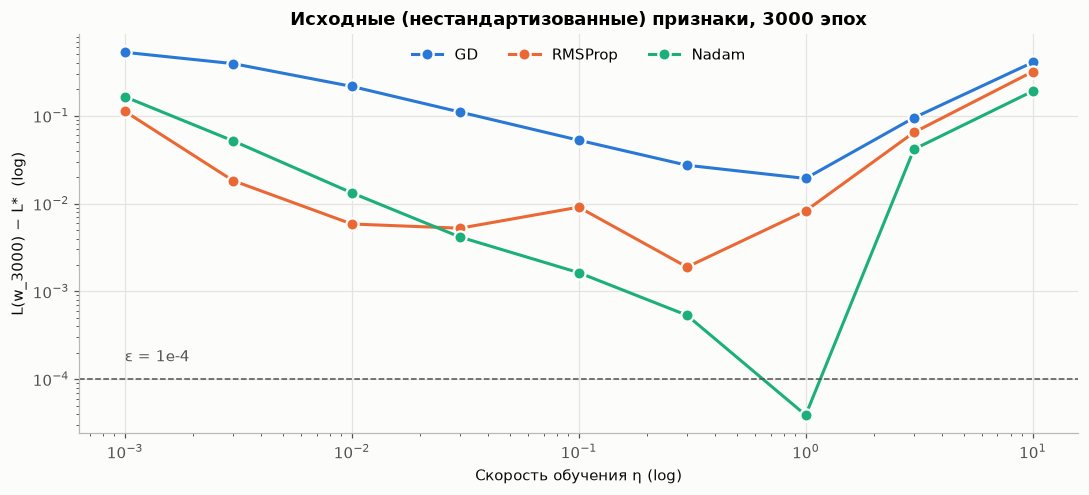

In [22]:
fig, ax = plt.subplots(figsize=(10, 4.6))
for name, grid in raw_grids.items():
    gap = grid['L(w_final) − L*'].to_numpy(dtype=float)
    gap = np.where(np.isfinite(gap), np.maximum(gap, 1e-16), np.nan)
    ax.plot(grid['Шаг η'], gap, marker='o', markersize=8, color=COLORS[name],
            markeredgecolor='#fcfcfb', markeredgewidth=1.5, label=name)
ax.axhline(EPS, color='#52514e', linestyle='--', linewidth=1)
ax.text(LR_GRID[0], EPS * 1.6, 'ε = 1e-4', color='#52514e')
ax.set(xscale='log', yscale='log', xlabel='Скорость обучения η (log)',
       ylabel=f'L(w_{N_EPOCHS_RAW}) − L*  (log)',
       title=f'Исходные (нестандартизованные) признаки, {N_EPOCHS_RAW} эпох')
ax.legend(loc='upper center', ncol=3)
plt.tight_layout()
plt.savefig(IMG_DIR / 'lr_sensitivity_raw.png', bbox_inches='tight')
plt.show()

## 10. Проверка корректности реализации

Для контроля сравним наши веса с `sklearn.linear_model.LogisticRegression` без регуляризации (`C=np.inf`).
`sklearn` используется **только для сверки**: решение выше полностью реализовано на `numpy`.

In [23]:
from sklearn.linear_model import LogisticRegression

sk_model = LogisticRegression(C=np.inf, max_iter=10_000, tol=1e-10).fit(X_train_s, y_train)
w_sk = np.r_[sk_model.intercept_, sk_model.coef_.ravel()]

check = pd.DataFrame(
    {'sklearn': w_sk, 'Ньютон (эталон)': w_star,
     **{name: res['model'].w_ for name, res in RESULTS.items()}},
    index=['w0 (intercept)'] + FEATURES,
)
display(check)

for name, res in RESULTS.items():
    diff = np.abs(res['model'].w_ - w_sk).max()
    same = np.array_equal(res['model'].predict(X_test_s), sk_model.predict(X_test_s))
    print(f'{name:8s}: max |w − w_sklearn| = {diff:.2e}; предсказания на test совпадают со sklearn: {same}')
print(f"sklearn accuracy (test): {accuracy(y_test, sk_model.predict(X_test_s)):.3f}")

,sklearn,Ньютон (эталон),GD,RMSProp,Nadam
w0 (intercept),0.4477,0.4477,0.4478,0.3985,0.4477
sepal length (cm),-1.1384,-1.1384,-1.1375,-1.0918,-1.1384
sepal width (cm),-0.8174,-0.8174,-0.8179,-0.7708,-0.8174
petal length (cm),5.5039,5.5039,5.5016,5.4934,5.5039
petal width (cm),6.5176,6.5176,6.5171,6.5594,6.5176


GD      : max |w − w_sklearn| = 2.30e-03; предсказания на test совпадают со sklearn: True
RMSProp : max |w − w_sklearn| = 4.92e-02; предсказания на test совпадают со sklearn: True
Nadam   : max |w − w_sklearn| = 2.81e-07; предсказания на test совпадают со sklearn: True
sklearn accuracy (test): 0.950


## 11. Выводы

### Итоговая таблица

| Метод | Шаг η | Метрика: accuracy (test) | Метрика: accuracy (CV 5×10) | Эпох до сходимости (ε = 10⁻⁴) | Время 1000 эпох* |
|---|---|---|---|---|---|
| Градиентный спуск (GD) | 10 | **0.950** | 0.959 ± 0.047 | 157 | ≈ 26 мс |
| RMSProp | 0.1 | **0.950** | 0.954 ± 0.051 | 120 | ≈ 28 мс |
| Nadam | 1 | **0.950** | 0.954 ± 0.051 | 158 | ≈ 34 мс |

\* Время зависит от компьютера. Точные значения текущего запуска — в таблице раздела 8.1.

### Что показал эксперимент

1. **Реализация корректна.** Аналитический градиент совпадает с численным (расхождение ~10⁻¹⁰). Веса, найденные всеми тремя методами, совпадают с эталоном (метод Ньютона) и с `sklearn`: у Nadam — до 3·10⁻⁷, у GD — до 2·10⁻³, у RMSProp — до 5·10⁻². Предсказания на тесте у всех трёх методов и у `sklearn` одинаковые.

2. **По метрике качества методы равны.** Accuracy на тесте — 0.95 у всех: одна ошибка из 20, объект на границе классов. На кросс-валидации — 0.954–0.959.
   Так и должно быть: log-loss выпуклая, и все методы пришли к одному и тому же минимуму, то есть к одной и той же модели. **Выбор оптимизатора влияет не на итоговое качество, а на то, сколько стоит его достичь и насколько надёжно это получается.**

3. **Скорость и характер сходимости различаются** (при лучшем η из одной сетки):
   * **GD** сходится линейно: на логарифмическом графике это прямая. Скорость ограничена обусловленностью гессиана (κ ≈ 26). Лучшим оказался большой шаг η = 10. Это не ошибка: вблизи минимума кривизна функции потерь мала, и устойчивыми остаются шаги до ≈ 126.
   * **RMSProp** первым входит в ε-окрестность минимума (120 эпох), но дальше не уточняет решение и остаётся на уровне ~4·10⁻⁵ над минимумом. Когда градиент стремится к нулю, знаменатель $\sqrt{E[g^2]}$ тоже стремится к нулю, эффективный шаг не уменьшается, и метод колеблется вокруг минимума. Это те самые «ёжики» RMSProp из статьи. Точное решение RMSProp даёт только при меньшем шаге (η = 0.01, 665 эпох).
   * **Nadam** проскакивает минимум за счёт импульса (это видно на траекториях) и возвращается. Затем сходится всё быстрее: к ~360-й эпохе разрыв меньше 10⁻¹², это самое точное решение из трёх.
   * **По времени** все методы укладываются в несколько миллисекунд до сходимости. Эпоха GD самая дешёвая: адаптивным методам нужно хранить и пересчитывать накопленные моменты, и эпоха у них дороже примерно на 10–40 % в зависимости от запуска. На таком объёме данных разница во времени несущественна.

4. **Чувствительность к шагу.** У каждого метода рабочий диапазон η шириной около порядка величины, но расположены они по-разному: GD — η ∈ {3, 10} (при η ≤ 1 за 1000 эпох не сходится), RMSProp — [0.01; 0.1], Nadam — [0.1; 1].
   Для GD подходящий шаг определяется кривизной конкретной задачи (≈ 1/λ гессиана) и меняется от данных к данным. В адаптивных методах η примерно равна величине шага в пространстве весов, поэтому её проще угадать заранее.

5. **Главное преимущество адаптивных методов видно на плохо обусловленной задаче** (раздел 9). Без стандартизации (κ(XᵀX) ≈ 12 000) **GD не сошёлся** за 3000 эпох ни при одном шаге: лучший разрыв 1.9·10⁻², accuracy на тесте 0.85. **RMSProp** дошёл до 1.9·10⁻³ (accuracy 0.95). **Nadam сошёлся** за 2501 эпоху (accuracy 0.95).
   Свой масштаб шага для каждого параметра плюс импульс компенсируют разный масштаб признаков. Практический вывод: для GD стандартизация признаков обязательна, для остальных методов она тоже полезна.

6. **Нюанс кросс-валидации.** Разница 0.959 против 0.954 набирается в 4 фолдах из 50. В них обучающая подвыборка оказалась линейно разделимой: конечного минимума log-loss нет, веса растут неограниченно, и результат зависит от траектории метода.
   GD на разделимых данных по направлению стремится к разделяющей гиперплоскости с максимальным зазором (Soudry et al., 2018), поэтому на этих фолдах ошибается на 1–2 объекта меньше. Это эффект неявной регуляризации, а не скорости оптимизации. С L2-регуляризацией это различие исчезло бы.

7. Максимум accuracy на кросс-валидации (≈ 0.96) все методы достигают уже к 50–100 эпохам. Дальнейшее обучение уточняет значение функции потерь, но метрику не улучшает.

### Рекомендации

* Для небольшой выпуклой задачи со **стандартизованными** признаками достаточно обычного **градиентного спуска**: он самый простой и дешёвый, нужно только подобрать шаг.
* **Nadam** — лучший выбор «по умолчанию». Он даёт самое точное решение, устойчив к масштабу признаков, и η ≈ 0.1–1 подходит без тонкой настройки. Это согласуется с рекомендацией статьи держать методы семейства Adam «золотым молотком».
* **RMSProp** быстро даёт приближённое решение, но для точной сходимости ему нужно уменьшать шаг: меньший η или затухание скорости обучения.

### Источники

1. П. Садовников. [Методы оптимизации нейронных сетей](https://habr.com/en/articles/318970/). Хабр, 2017.
2. S. Ruder. [An overview of gradient descent optimization algorithms](https://arxiv.org/abs/1609.04747). 2016.
3. T. Dozat. [Incorporating Nesterov Momentum into Adam](https://openreview.net/pdf/OM0jvwB8jIp57ZJjtNEZ.pdf). ICLR Workshop, 2016.
4. D. Soudry et al. [The Implicit Bias of Gradient Descent on Separable Data](https://jmlr.org/papers/v19/18-188.html). JMLR, 2018.
5. [sklearn.datasets.load_iris](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_iris.html); [PCA on Iris Dataset](https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html).